# Channel Effectiveness & ROI Analysis

## Marketing Mix Modelling (MMM)

This notebook analyses advertising channel effectiveness using the trained
Marketing Mix Model (MMM). The objective is to compare channel spending,
evaluate model-based channel responses, analyse marketing efficiency, and
provide insights to support budget optimisation.

### Channels Analysed
- TV
- Facebook/Instagram
- Google Search
- YouTube
- Radio
- Outdoor


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../../data/processed/cleaned_data.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (36, 25)


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,conversions,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count,data_type
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,1210051,0.998,7.27,49.6,56.8,324.42,1.000,1.08,2,SYNTHETIC
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,664746,1.017,9.47,51.0,58.4,335.92,1.012,0.96,6,SYNTHETIC
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,380625,1.011,6.83,45.9,60.6,328.66,1.024,1.00,2,SYNTHETIC
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,1228413,1.017,21.52,31.2,54.5,325.60,1.037,1.19,6,SYNTHETIC
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,562986,1.014,1.95,53.0,56.5,330.03,1.049,1.10,3,SYNTHETIC


# Channel Effectiveness & ROI Analysis

## Objective

This notebook evaluates the effectiveness of six advertising channels using
historical advertising data and the trained Marketing Mix Model (MMM).

The analysis focuses on:

1. Advertising spend distribution across channels.
2. Historical channel spending patterns.
3. Model-based channel effectiveness.
4. Advertising response analysis.
5. Marketing efficiency evaluation.
6. Key findings to support budget optimisation.

## Channels Analysed

- TV
- Facebook / Instagram
- Google Search
- YouTube
- Radio
- Outdoor

## 1. Data Overview

The cleaned dataset contains monthly advertising expenditure, sales revenue,
and external market variables from January 2023 to December 2025.

This section confirms the dataset structure before performing channel
effectiveness analysis.


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 36
Columns: 25


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,conversions,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count,data_type
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,1210051,0.998,7.27,49.6,56.8,324.42,1.000,1.08,2,SYNTHETIC
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,664746,1.017,9.47,51.0,58.4,335.92,1.012,0.96,6,SYNTHETIC
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,380625,1.011,6.83,45.9,60.6,328.66,1.024,1.00,2,SYNTHETIC
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,1228413,1.017,21.52,31.2,54.5,325.60,1.037,1.19,6,SYNTHETIC
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,562986,1.014,1.95,53.0,56.5,330.03,1.049,1.10,3,SYNTHETIC


## 2. Advertising Spend Analysis

This section examines historical advertising expenditure across the six
marketing channels. The objective is to understand how the advertising
budget has been distributed and identify channels that received the
greatest share of investment.

The results will later be compared with model-based effectiveness
measures to determine whether higher spending corresponds to stronger
estimated responses.

In [4]:
channels = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

In [5]:
spend_summary = pd.DataFrame({
    "Channel": channels,
    "Total_Spend_LKR": [df[ch].sum() for ch in channels],
    "Average_Spend_LKR": [df[ch].mean() for ch in channels],
    "Min_Spend_LKR": [df[ch].min() for ch in channels],
    "Max_Spend_LKR": [df[ch].max() for ch in channels]
})

spend_summary["Spend_Share_Percent"] = (
    spend_summary["Total_Spend_LKR"]
    / spend_summary["Total_Spend_LKR"].sum()
) * 100

spend_summary = spend_summary.sort_values(
    by="Total_Spend_LKR",
    ascending=False
)

spend_summary


,Channel,Total_Spend_LKR,Average_Spend_LKR,Min_Spend_LKR,Max_Spend_LKR,Spend_Share_Percent
1,facebook_instagram_spend_lkr,158343617,4.398434e+06,3067341,6030031,23.677886
0,tv_spend_lkr,156964242,4.360118e+06,2638465,6020432,23.471621
2,google_search_spend_lkr,119353135,3.315365e+06,2162014,5096864,17.847451
5,outdoor_spend_lkr,94057802,2.612717e+06,1727984,3690845,14.064917
3,youtube_spend_lkr,79913729,2.219826e+06,1476724,3178264,11.949886
4,radio_spend_lkr,60107999,1.669667e+06,1217450,2169012,8.988239


### Advertising Spend by Channel

The following chart compares total advertising expenditure across the six
marketing channels during the 36-month study period.


C:\Users\User\AppData\Local\Temp\ipykernel_9232\3680587830.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


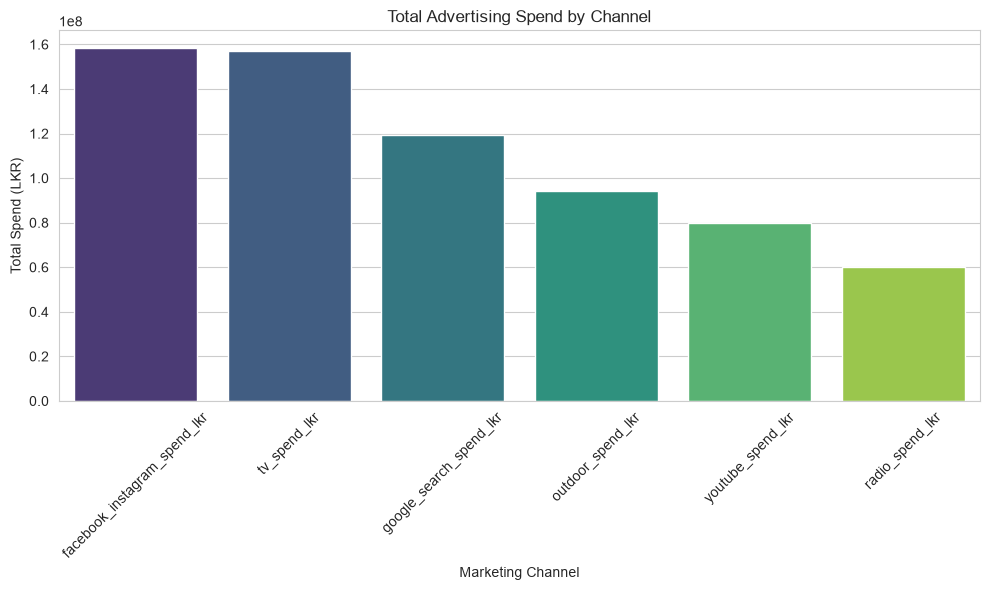

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.barplot(
    data=spend_summary,
    x="Channel",
    y="Total_Spend_LKR",
    palette="viridis"
)

plt.title("Total Advertising Spend by Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Spend (LKR)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


## 3. Historical Channel Spending Comparison

While the previous analysis examined total spending across channels,
this section investigates how advertising expenditure changed over time.

Understanding temporal spending patterns helps identify seasonality,
budget allocation trends, and periods of increased or reduced marketing
investment.


In [7]:
df["month"] = pd.to_datetime(df["month"])

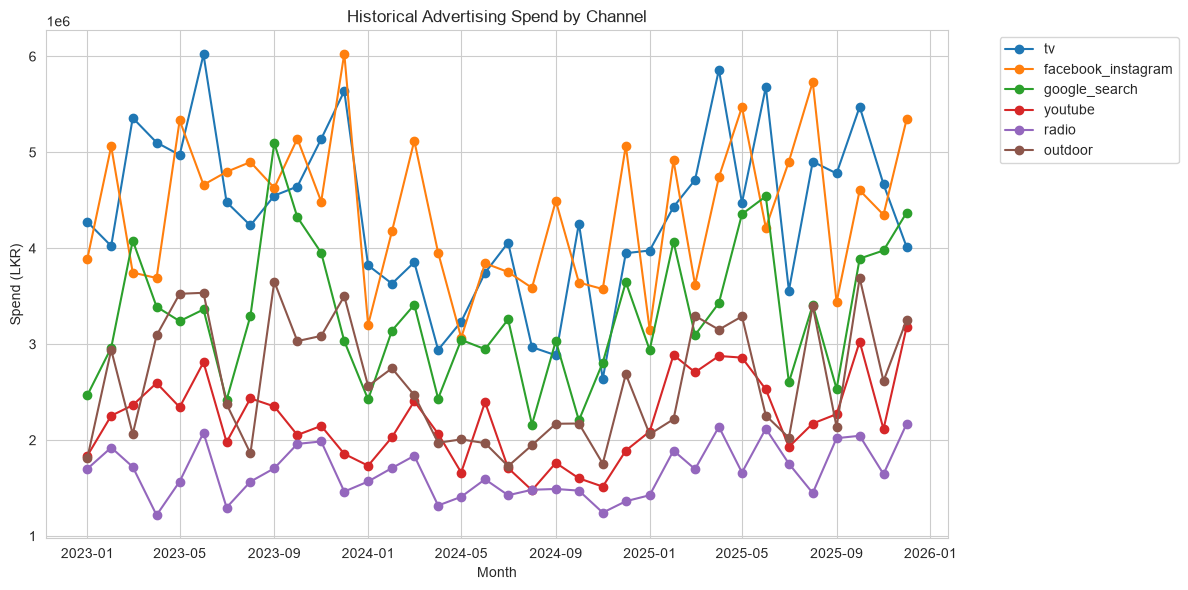

In [8]:
plt.figure(figsize=(12,6))

for channel in channels:
    plt.plot(
        df["month"],
        df[channel],
        marker="o",
        label=channel.replace("_spend_lkr", "")
    )

plt.title("Historical Advertising Spend by Channel")
plt.xlabel("Month")
plt.ylabel("Spend (LKR)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Interpretation

The historical spending trends show that Facebook/Instagram and TV
consistently received the highest advertising budgets throughout the
36-month period.

Google Search maintained a moderate level of investment, while Radio
consistently received the lowest spending allocation.

Several channels exhibit noticeable month-to-month fluctuations,
indicating that advertising budgets were adjusted over time rather than
remaining fixed. However, no strong long-term upward or downward trend
is immediately visible.

These observations describe spending behaviour only. Further analysis
using the trained MMM model is required to determine whether heavily
funded channels correspond to stronger sales responses.

## 4. Model-Based Channel Effectiveness Analysis

In [9]:
import joblib

bundle = joblib.load("../../models/mmm_model.joblib")

print(bundle.keys())

dict_keys(['estimator', 'model_name', 'feature_variant', 'feature_columns', 'target', 'saturation_midpoints', 'saturation_slope', 'training_end_month', 'selected_by', 'cv_fold_count', 'cv_rmse_lkr_mean', 'cv_rmse_lkr_std', 'holdout_start_month', 'holdout_end_month', 'evaluation_method', 'adstock_decay_rates', 'previous_adstock_reference_month', 'previous_adstock_reference', 'external_factors_reference'])


## 4. Model-Based Channel Effectiveness Analysis

The previous sections examined historical spending patterns. However,
spending levels alone do not indicate advertising effectiveness.

This section uses the trained Marketing Mix Model (MMM) to investigate
how predicted sales respond to changes in channel budgets.

The analysis is based on model predictions and should not be interpreted
as causal attribution or proven ROI.

In [10]:
feature_columns = bundle["feature_columns"]

print("Number of Features:", len(feature_columns))
print()

for col in feature_columns:
    print(col)

Number of Features: 16

tv_adstock_lkr_saturated
facebook_instagram_adstock_lkr_saturated
google_search_adstock_lkr_saturated
youtube_adstock_lkr_saturated
radio_adstock_lkr_saturated
outdoor_adstock_lkr_saturated
average_price_index
promotion_discount_pct
competitor_pressure_index_0_100
economic_sentiment_index_0_100
lkr_usd_exchange_rate
inflation_proxy_index
seasonal_demand_index
public_holiday_count
month_sin
month_cos


In [11]:
print("Model Type:", bundle["model_name"])
print("Feature Variant:", bundle["feature_variant"])
print("Saturation Slope:", bundle["saturation_slope"])
print()

print("Adstock Decay Rates:")
print(bundle["adstock_decay_rates"])

Model Type: saturated_ridge_regression
Feature Variant: hill_saturated
Saturation Slope: 1.5

Adstock Decay Rates:
{'tv_spend_lkr': 0.6, 'facebook_instagram_spend_lkr': 0.3, 'google_search_spend_lkr': 0.2, 'youtube_spend_lkr': 0.4, 'radio_spend_lkr': 0.4, 'outdoor_spend_lkr': 0.5}


## 5. Channel Response Analysis

This section evaluates how predicted sales change when advertising budgets
are adjusted for individual channels.

The analysis uses the trained MMM model and keeps external factors fixed
at the reference values supplied with the model bundle.

Results should be interpreted as model-based predictions rather than
causal advertising effects.


In [12]:
import sys
from pathlib import Path

project_root = Path("../../").resolve()

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.predict_sales import (
    predict_budget_allocation,
    SPEND_CHANNELS,
    ADSTOCK_CHANNELS
)

In [13]:
reference_controls = bundle["external_factors_reference"]
reference_adstock = bundle["previous_adstock_reference"]

print("Control Variables:", len(reference_controls))
print("Adstock Variables:", len(reference_adstock))

Control Variables: 10
Adstock Variables: 6


### Budget Sensitivity Experiment

To evaluate channel effectiveness, each channel budget is increased by
10% while all other channel budgets and external factors remain fixed.

The resulting change in predicted sales is used as a model-based measure
of channel responsiveness.

These results represent model predictions only and should not be
interpreted as causal marketing effects.

In [14]:
baseline_allocation = {
    channel: df[channel].mean()
    for channel in SPEND_CHANNELS
}

baseline_prediction = predict_budget_allocation(
    allocation=baseline_allocation,
    external_factors=reference_controls,
    previous_adstock=reference_adstock
)

print(f"Baseline Predicted Revenue: LKR {baseline_prediction:,.0f}")

Baseline Predicted Revenue: LKR 96,065,072


In [15]:
effectiveness_results = []

for channel in SPEND_CHANNELS:

    test_allocation = baseline_allocation.copy()

    # Increase one channel by 10%
    test_allocation[channel] *= 1.10

    new_prediction = predict_budget_allocation(
        allocation=test_allocation,
        external_factors=reference_controls,
        previous_adstock=reference_adstock
    )

    sales_change = new_prediction - baseline_prediction

    effectiveness_results.append({
        "Channel": channel,
        "Baseline_Spend": baseline_allocation[channel],
        "New_Spend": test_allocation[channel],
        "Predicted_Sales_Change_LKR": sales_change
    })

effectiveness_df = pd.DataFrame(effectiveness_results)

effectiveness_df.sort_values(
    by="Predicted_Sales_Change_LKR",
    ascending=False,
    inplace=True
)

effectiveness_df

,Channel,Baseline_Spend,New_Spend,Predicted_Sales_Change_LKR
2,google_search_spend_lkr,3.315365e+06,3.646901e+06,536925.104455
3,youtube_spend_lkr,2.219826e+06,2.441808e+06,302869.803956
1,facebook_instagram_spend_lkr,4.398434e+06,4.838277e+06,193995.672613
0,tv_spend_lkr,4.360118e+06,4.796130e+06,188777.213737
5,outdoor_spend_lkr,2.612717e+06,2.873988e+06,93914.059722
4,radio_spend_lkr,1.669667e+06,1.836633e+06,-41426.744080


The negative estimated response for Radio should not be interpreted as
evidence that Radio advertising reduces sales. Instead, it reflects a
negative conditional association learned by the predictive model under
the specific assumptions and historical data available.

### Channel Effectiveness Comparison

C:\Users\User\AppData\Local\Temp\ipykernel_9232\2228750326.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


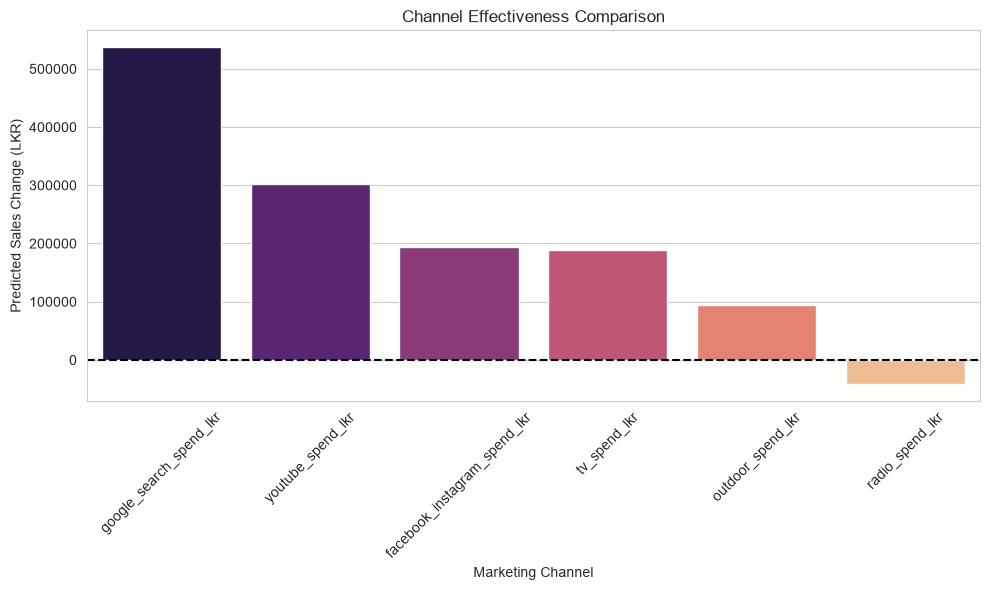

In [25]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=effectiveness_df,
    x="Channel",
    y="Predicted_Sales_Change_LKR",
    palette="magma"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--"
)

plt.title("Channel Effectiveness Comparison")
plt.xlabel("Marketing Channel")
plt.ylabel("Predicted Sales Change (LKR)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../../outputs/optimization/channel_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Google Search generated the largest predicted sales increase when its
budget was increased by 10%, followed by YouTube.

Facebook/Instagram and TV demonstrated moderate positive responses,
while Outdoor produced a smaller positive effect.

Radio exhibited a negative model-estimated response under the reference
scenario, consistent with observations reported during MMM model
evaluation. This result should be interpreted as a conditional model
association rather than a causal marketing effect.

Overall, the model suggests that digital advertising channels,
particularly Google Search and YouTube, may provide stronger marginal
responses than traditional channels under the simulated conditions.

## 6. Advertising Response Curves

This section evaluates how predicted sales change across different budget
levels for each advertising channel.

For each channel, spending is varied across its historical spending range
while all other channels and external factors remain fixed.

The resulting response curves illustrate how the trained MMM estimates
the relationship between advertising investment and predicted sales.

These curves should be interpreted as model-based forecasts rather than
causal advertising effects.

In [17]:
response_curves = {}

for channel in SPEND_CHANNELS:

    spend_range = np.linspace(
        df[channel].min(),
        df[channel].max(),
        20
    )

    predictions = []

    for spend in spend_range:

        allocation = baseline_allocation.copy()
        allocation[channel] = spend

        sales_prediction = predict_budget_allocation(
            allocation=allocation,
            external_factors=reference_controls,
            previous_adstock=reference_adstock
        )

        predictions.append(sales_prediction)

    response_curves[channel] = {
        "spend": spend_range,
        "sales": predictions
    }

print("Response curves generated successfully.")

Response curves generated successfully.


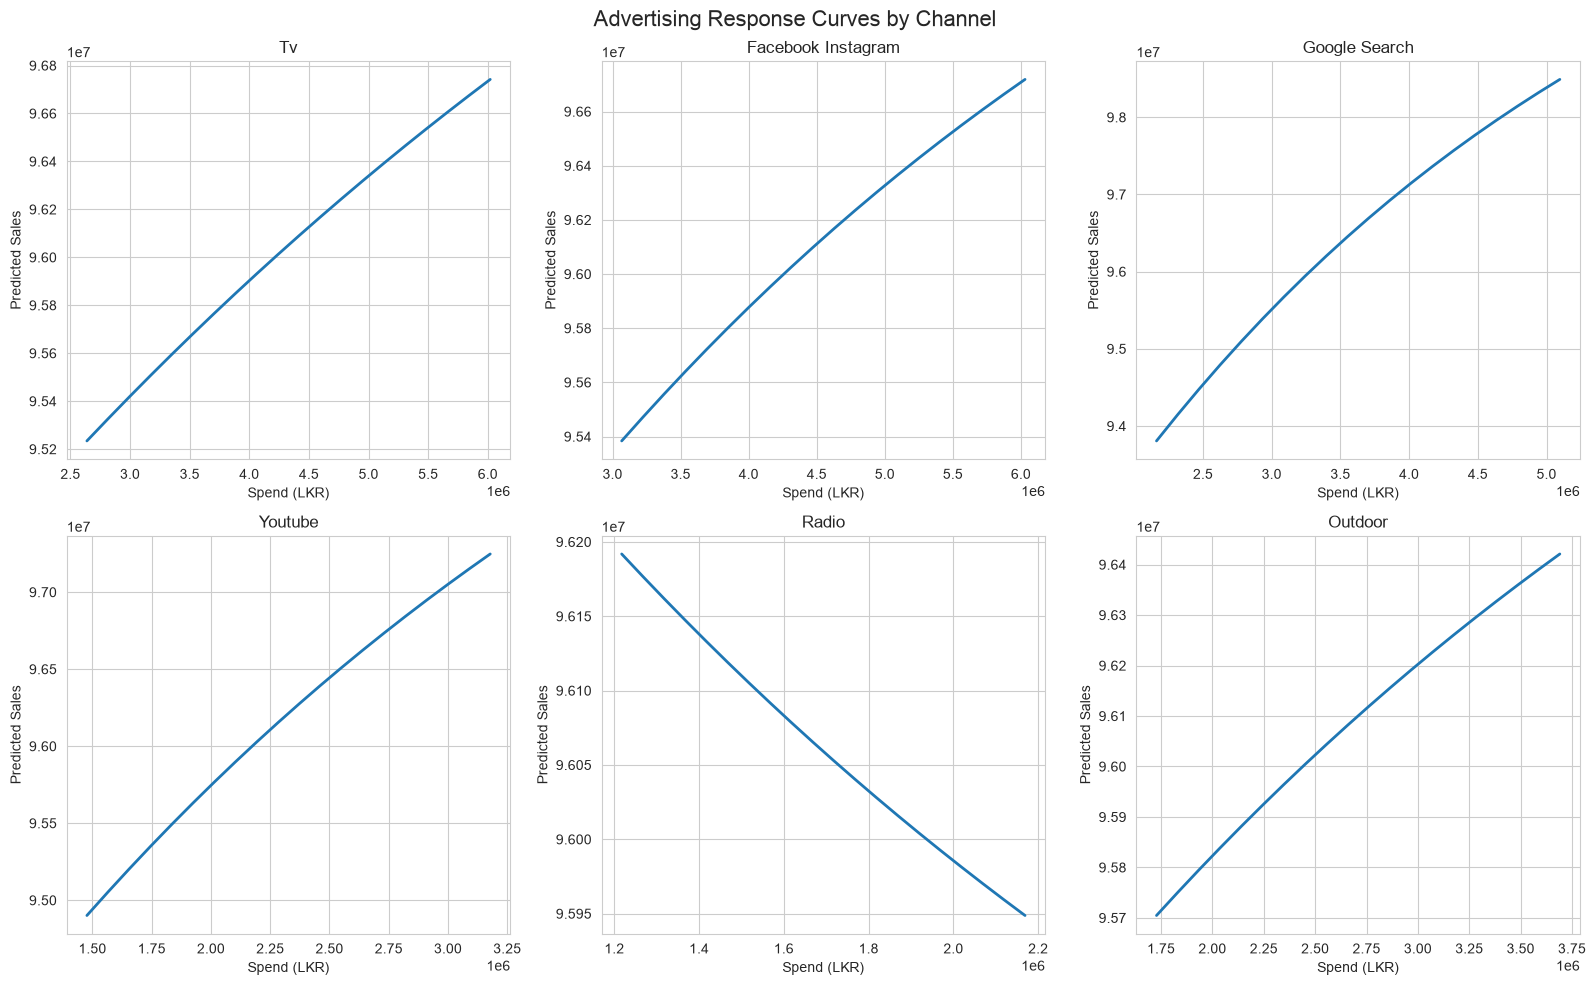

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, channel in enumerate(SPEND_CHANNELS):

    ax = axes[i]

    ax.plot(
        response_curves[channel]["spend"],
        response_curves[channel]["sales"],
        linewidth=2
    )

    ax.set_title(
        channel.replace("_spend_lkr", "").replace("_", " ").title()
    )

    ax.set_xlabel("Spend (LKR)")
    ax.set_ylabel("Predicted Sales")

    ax.grid(True)

plt.suptitle(
    "Advertising Response Curves by Channel",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "../../outputs/optimization/channel_response_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

The response curves illustrate how predicted sales change when
advertising spend is varied across the historical range of each channel.

Google Search exhibits the strongest positive response, indicating that
increased investment in this channel is associated with large increases
in predicted sales under the model.

YouTube also demonstrates a strong positive response, while Facebook/
Instagram and TV exhibit moderate positive responses.

Outdoor displays a weaker positive effect, suggesting lower marginal
returns relative to other channels.

Radio demonstrates a negative model-estimated response across the
evaluated range. This result is consistent with observations reported in
the MMM evaluation and should not be interpreted as evidence of a causal
negative advertising impact.

Overall, the response curves indicate that digital channels, especially
Google Search and YouTube, provide stronger estimated marginal responses
than traditional channels under the modeled conditions.

## 7. Marketing Efficiency Analysis

The project requirements specify channel effectiveness and ROI analysis.

However, the MMM evaluation report notes that predictive model outputs
should not be interpreted as causal attribution. Therefore, true ROI
cannot be reliably calculated without additional profit, margin, and
incrementality assumptions.

Instead, this section evaluates marketing efficiency using model-based
response measures and advertising spend data.

In [20]:
effectiveness_df["Spend_Increase_LKR"] = (
    effectiveness_df["New_Spend"]
    - effectiveness_df["Baseline_Spend"]
)

effectiveness_df["Response_Efficiency"] = (
    effectiveness_df["Predicted_Sales_Change_LKR"]
    / effectiveness_df["Spend_Increase_LKR"]
)

effectiveness_df


,Channel,Baseline_Spend,New_Spend,Predicted_Sales_Change_LKR,Spend_Increase_LKR,Response_Efficiency
2,google_search_spend_lkr,3.315365e+06,3.646901e+06,536925.104455,331536.486111,1.619505
3,youtube_spend_lkr,2.219826e+06,2.441808e+06,302869.803956,221982.580556,1.364385
1,facebook_instagram_spend_lkr,4.398434e+06,4.838277e+06,193995.672613,439843.380556,0.441056
0,tv_spend_lkr,4.360118e+06,4.796130e+06,188777.213737,436011.783333,0.432964
5,outdoor_spend_lkr,2.612717e+06,2.873988e+06,93914.059722,261271.672222,0.359450
4,radio_spend_lkr,1.669667e+06,1.836633e+06,-41426.744080,166966.663889,-0.248114


C:\Users\User\AppData\Local\Temp\ipykernel_9232\1477744308.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


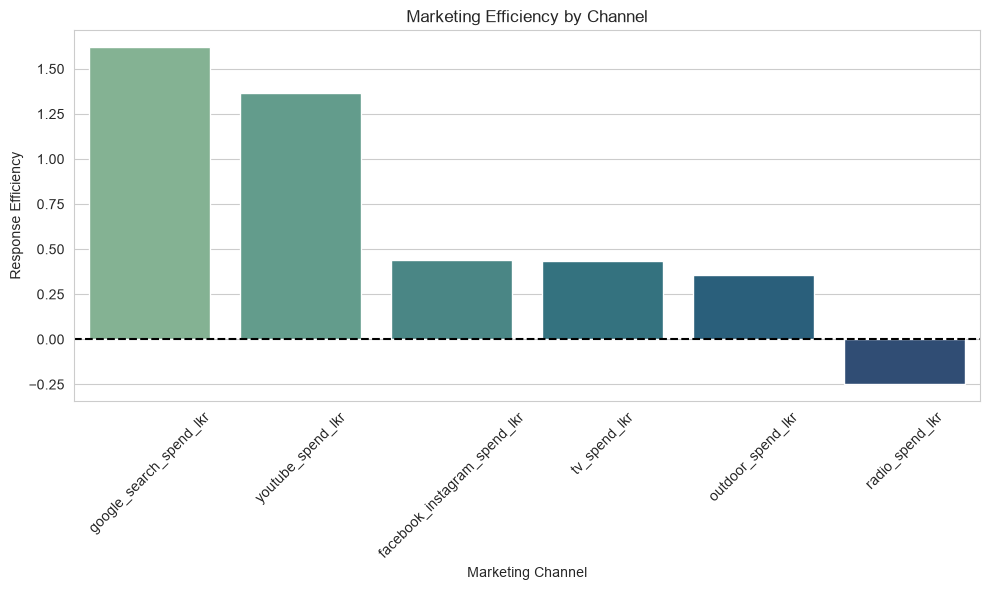

In [21]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=effectiveness_df,
    x="Channel",
    y="Response_Efficiency",
    palette="crest"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--"
)

plt.title("Marketing Efficiency by Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Response Efficiency")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


### Interpretation

Response efficiency compares the estimated change in predicted sales with
the additional advertising spend applied during the budget sensitivity
experiment.

Google Search demonstrates the highest estimated efficiency, indicating
that additional spending generated the largest predicted sales response
relative to the budget increase.

YouTube also shows strong efficiency, while Facebook/Instagram and TV
produce moderate positive responses.

Outdoor exhibits lower efficiency, suggesting smaller predicted sales
returns for additional expenditure.

Radio produces a negative model-estimated efficiency under the reference
scenario. Consistent with previous MMM findings, this should be
interpreted as a model association rather than evidence of negative
advertising effectiveness.

Because profit margins and causal attribution are unavailable, these
results should not be interpreted as true ROI estimates.

In [22]:
effectiveness_df[[
    "Channel",
    "Response_Efficiency"
]]

,Channel,Response_Efficiency
2,google_search_spend_lkr,1.619505
3,youtube_spend_lkr,1.364385
1,facebook_instagram_spend_lkr,0.441056
0,tv_spend_lkr,0.432964
5,outdoor_spend_lkr,0.359450
4,radio_spend_lkr,-0.248114


## 8. Channel Performance Summary

This section consolidates spending, effectiveness, and efficiency
results into a single comparison table.

The summary provides an overall view of channel performance and
identifies channels with stronger and weaker estimated responses under
the trained MMM model.

In [23]:
channel_performance = spend_summary.copy()

channel_performance = channel_performance.merge(
    effectiveness_df[
        [
            "Channel",
            "Predicted_Sales_Change_LKR",
            "Response_Efficiency"
        ]
    ],
    on="Channel",
    how="left"
)

channel_performance["Performance_Rank"] = (
    channel_performance["Response_Efficiency"]
    .rank(ascending=False)
    .astype(int)
)

channel_performance = channel_performance.sort_values(
    by="Performance_Rank"
)

channel_performance

,Channel,Total_Spend_LKR,Average_Spend_LKR,Min_Spend_LKR,Max_Spend_LKR,Spend_Share_Percent,Predicted_Sales_Change_LKR,Response_Efficiency,Performance_Rank
2,google_search_spend_lkr,119353135,3.315365e+06,2162014,5096864,17.847451,536925.104455,1.619505,1
4,youtube_spend_lkr,79913729,2.219826e+06,1476724,3178264,11.949886,302869.803956,1.364385,2
0,facebook_instagram_spend_lkr,158343617,4.398434e+06,3067341,6030031,23.677886,193995.672613,0.441056,3
1,tv_spend_lkr,156964242,4.360118e+06,2638465,6020432,23.471621,188777.213737,0.432964,4
3,outdoor_spend_lkr,94057802,2.612717e+06,1727984,3690845,14.064917,93914.059722,0.359450,5
5,radio_spend_lkr,60107999,1.669667e+06,1217450,2169012,8.988239,-41426.744080,-0.248114,6


### Interpretation

The combined performance summary indicates that Google Search and
YouTube are the strongest performing channels according to the model.

These channels demonstrate both high predicted sales responses and high
response efficiency when advertising budgets are increased.

Facebook/Instagram and TV receive the largest share of historical
advertising expenditure but exhibit lower marginal response efficiency
than Google Search and YouTube, suggesting possible saturation effects.

Outdoor produces positive but relatively modest estimated responses.

Radio consistently demonstrates the weakest performance according to the
model and should be investigated further before being prioritised in
future optimisation exercises.

These findings are model-based estimates and should not be interpreted
as causal measures of advertising effectiveness.

## 9. Findings and Limitations

### Key Findings

1. Facebook/Instagram and TV received the largest share of historical advertising expenditure, accounting for approximately 47% of the total marketing budget.

2. Google Search demonstrated the strongest model-estimated response and achieved the highest efficiency score among all channels.

3. YouTube generated the second strongest response and efficiency performance despite receiving a smaller proportion of the advertising budget.

4. Facebook/Instagram and TV exhibited moderate marginal responses compared with Google Search and YouTube, suggesting possible diminishing returns under the fitted MMM model.

5. Outdoor advertising produced positive but relatively limited estimated responses.

6. Radio displayed a negative model-estimated response under the reference scenario. This finding is consistent with Part 02 model evaluation results and should be interpreted as a conditional association rather than causal evidence.

### Limitations

1. The dataset contains only 36 monthly observations, limiting statistical robustness.

2. Results are derived from a predictive Marketing Mix Model and do not represent causal attribution.

3. Adstock carryover assumptions and Hill saturation parameters influence estimated responses.

4. Profit margins and causal incrementality measures were unavailable; therefore, true ROI could not be calculated.

5. The analysis should be interpreted as scenario-based forecasting rather than guaranteed future performance.

### Support for Budget Optimisation

The spending ranges, response curves, effectiveness measures, and efficiency rankings generated in this analysis should be supplied to Member 2 for budget optimisation modelling.

Particular attention should be given to Google Search and YouTube, which demonstrated the strongest estimated marginal responses under the MMM framework.

In [24]:
channel_performance.to_csv(
    "../../outputs/optimization/channel_effectiveness.csv",
    index=False
)

print("channel_effectiveness.csv saved successfully.")


channel_effectiveness.csv saved successfully.


### ROI / ROAS Considerations

True ROI could not be calculated because profit margin,
incrementality, and attributed revenue information were not
available.

As recommended in Part 02 findings, model-based response
metrics and efficiency measures were reported instead of
claiming causal ROI estimates.